### [GALT] Vežba 3: Raspodela zvezda u Galaksiji

### <font color='yellow'> Ideja vežbe: Određivanje Galaktičkog potencijala i rotacione krive iz sintetičke populacije zvezda. </font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod

U prošloj vežbi, generisali smo sintetičku populaciju zvezda koja prati Salpeterov zakon:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
U nastavku smo pretpostavili da su zvezde ravnomerno raspoređene u sferi, da bismo analizirali Malmkvisnovu neobjektivnost. Međutim, mi znamo da raspodela zvezda (i generalno materije) u Galaksiji nije uniformna.

Pretpostavimo da je prostorna gustina zvezda opisana eksponencijalnim diskom:

$$
\rho(R,z)=\rho_0\exp(-R/R_d)\exp(-|z|/z_d),
$$

gde su R i z cilindrične koordinate, $R_d$ i $z_d$ skala diska i visinska skala. Ugao $\varphi$ je uniforman na $(0,2\pi)$.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

##### <font color="green">1. Semplovati 100 000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Ovo je iz prethodne vežbe.)</font>

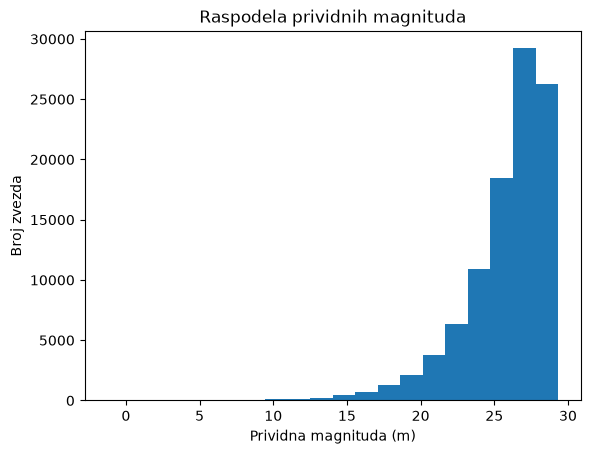

In [8]:
np.random.seed(42)
#Parametri koje koristimo u zadatku
alpha = 2.35
M_min = 0.08 
M_max = 200
N = 100000 
#generisemo N slicajnih brojeve
u = np.random.uniform(0, 1, N)
#inverzna finkcija za mase
mase = (M_min**(1-alpha) + u*(M_max**(1-alpha) - M_min**(1-alpha)))**(1/(1-alpha))

#relacija luminoznosti i mase 
L = mase**3.5
#apsolutna magnituda
M_abs = 4.74 - 2.5*np.log10(L)

u_r = np.random.uniform(0, 1, N)
#maksimalna udaljenost
d = 10000 #pc
#generisanje udaljenosti zvezda
r = d * u_r**(1/3)
#zapremina sfere
V = (4/3)*d**3 * np.pi 
#prividna magnituda
m = M_abs + 5*np.log10(r) - 5
#plot histograma
plt.hist(m, bins=20)
plt.xlabel("Prividna magnituda (m)")
plt.ylabel("Broj zvezda")
plt.title("Raspodela prividnih magnituda")
plt.show()

Najviše je zvezda male mase a masivne zvezde su retke. Histogram približno prati Salpeterov zakon. Na velikim masama odstupanja su veća jer je tamo malo zvezda.

##### <font color="green">2. Semplovati cilindrične koordinate za svaku zvezdu. (Uzeti, npr. $R_d$ = 3kpc i $z_d$ = 0.2kpc.) Objasniti kako se semplovanje vrši. </font>

In [12]:
R_d = 3.0 #kpc radijalni deo diska
z_d = 0.2 #kpc vertikalni deo diska
#rasporedjujemo po eksponencijalnom zakonu na random pozicijama 
R1 = np.random.exponential(R_d, N) #imamo dve nezavisne promenljive (mislim i na ovu ispod)
R2 = np.random.exponential(R_d, N)
R_zvezde = R1 + R2 #dobijamo raspodelu po radijusu R

z_abs = np.random.exponential(z_d, N) #zato sto eksponencijalna generise samo pozitivne 
znak = np.random.choice([-1, 1], N) #nasumicno biramo znak
z_zvezde = znak * z_abs #sada imamo i negativne 

fi = np.random.uniform(0, 2*np.pi, N) #semplovanje po fi
#Transfromacija u polarne koo.
x = R_zvezde * np.cos(fi)
y = R_zvezde * np.sin(fi)
#printijemo dobijene verednosti na ovaj nacin i ocekivane vrednosti 
print(f"Srednje R: {R_zvezde.mean():.3f} kpc (očekivano {2*R_d:.1f})")
print(f"Srednje(apsolutno) |z|: {np.abs(z_zvezde).mean():.3f} kpc (očekivano {z_d})")
print(f"Srednje z: {z_zvezde.mean():.4f} kpc (očekivano 0)")

Srednje R: 5.996 kpc (očekivano 6.0)
Srednje(apsolutno) |z|: 0.200 kpc (očekivano 0.2)
Srednje z: 0.0011 kpc (očekivano 0)


U ovom delu simuliramo prostornu raspodelu zvezda u galaktickom disku (u ovom slucaju u cilindru). Za raspodelu smo koristili eksponencijalnu raspodelu po R , z . So bi znacilo da smo semplovali po radijusu visini cilindra i uglu $fi$.

##### <font color="green">3. Prikazati raspodelu zvezda u 3D, kao i (R, z) i (x, y) ravni.</font>

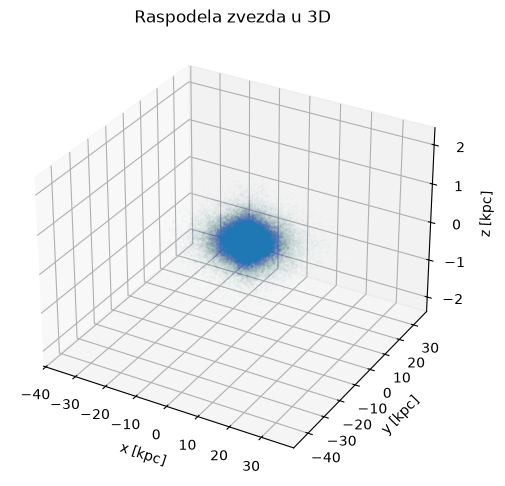

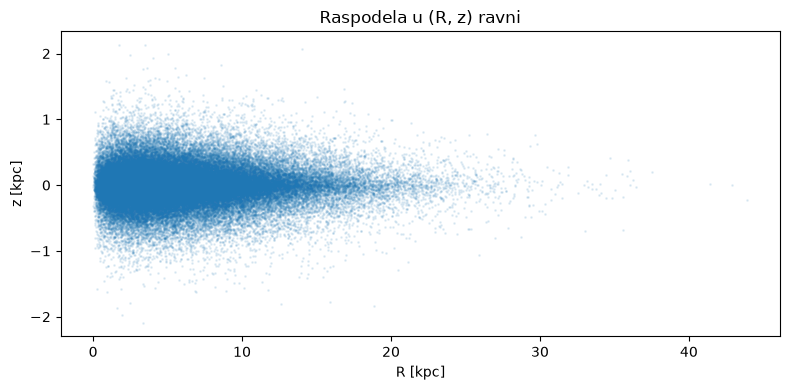

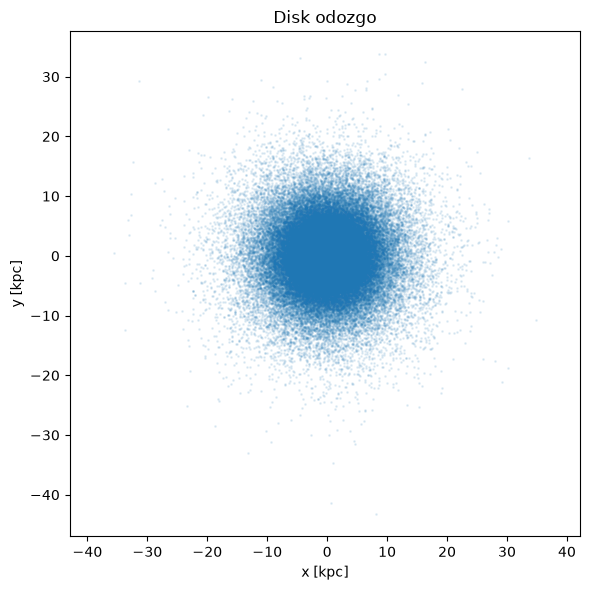

In [13]:
#pravimo 3D plot semplovanih podataka
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x, y, z_zvezde, s=1, alpha=0.1) #sada koristimo onu transformaciju u polarne koo.
ax.set_xlabel("x [kpc]")
ax.set_ylabel("y [kpc]")
ax.set_zlabel("z [kpc]")
ax.set_title("Raspodela zvezda u 3D")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(R_zvezde, z_zvezde, s=1, alpha=0.1)
plt.xlabel("R [kpc]")
plt.ylabel("z [kpc]")
plt.title("Raspodela u (R, z) ravni")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(x, y, s=1, alpha=0.1)
plt.xlabel("x [kpc]")
plt.ylabel("y [kpc]")
plt.title("Disk odozgo")
plt.axis("equal")
plt.tight_layout()
plt.show()

U $(x,y)$ ravni vidi se priblizno kruzna raspodela. U $(R,z)$ ravni vidi se da je većina zvezda blizu $z=0$.

Potrebno je odraditi normalizaciju, tako da celi disk ima masu $M_{disk}$. Uzeti, npr. $M_{disk}=5\cdot 10^{10}M_\odot$. Dakle, ako integralimo prethodno zadatku gustinu po zapremini, možemo da odredimo vrednost $\rho_0$. 

##### <font color="green">4. Izračunati $\rho_0$.</font>

In [14]:
M_disk = 5e10      # M_sun
rho0 = M_disk / (4 * np.pi * R_d**2 * z_d)

print(f"rho0 = {rho0:.3e} M_sun/kpc^3")
print(f"rho0 = {rho0 / 1e9:.3f} M_sun/pc^3")

rho0 = 2.210e+09 M_sun/kpc^3
rho0 = 2.210 M_sun/pc^3


Ro dobijamo iz Mase diska posto je masa diska jednak proizvodu gustine, 4pi jer smo integralili po uglu kao i $R_d$ i $z_d$. Vrednosti gustine smo prikazali iznad.

Dalje, koristeći Poasonovu jednačinu: 

$$\nabla^2 \Phi = 4\pi G\rho$$

možemo da odredimo Galaktički potencijal koji odgovara zadatoj raspodeli gustine.

Poasonova jednačina u cilindričnim koordinatama:

$$ \frac{1}{R}\frac{\partial}{\partial R}
\left(R\frac{\partial\Phi}{\partial R}\right)
+\frac{\partial^2\Phi}{\partial z^2}
=4\pi G\rho(R,z).
$$

Koristiti metodu konačnih razlika na dvodimenzionalnoj mreži $(R,z)$, za oblast $0\leq R\leq30\mathrm{kpc}$ i $-10\leq z\leq10\mathrm{kpc}$.

Primeniti sledeće granične uslove:

Na spoljnim granicama oblasti pretpostaviti da se potencijal približava potencijalu tačkaste mase ukupne mase diska:

$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+z^2}}.
$$

Na osi simetrije (R=0) primeniti uslov:

$$
\left.\frac{\partial\Phi}{\partial R}\right|_{R=0}=0.
$$

U nastavku je napisana funkcija solve_poisson koja numerički rešava ovaj problem.

In [17]:
def solve_poisson(rho, R, z, M, G):

    # broj tačaka numeričke mreže u R i z pravcu
    NR = len(R)
    NZ = len(z)

    # korak
    dR = R[1] - R[0]
    dz = z[1] - z[0]

    # na spoljnim granicama unapred zadajemo potencijal, pa ne moramo da ga racunamo kao nepoznatu
    nR = NR - 1
    nZ = NZ - 2

    # ukupan broj tačaka u kojima računamo vrednosti potencijala
    N = nR * nZ

    # 2D mrežu (i,j) preslikavamo u 1D indeks k, jer sistem rešavamo u obliku matrice A i vektora b
    def idx(i, j):
        return i * nZ + (j - 1)

    # formiramo praznu matricu A
    # koristimo lil_matrix jer je većina elemenata matrice nula
    A = lil_matrix((N, N))

    # desna strana Poasonove jednacine: 4*pi*G*rho
    b = (4 * np.pi * G * rho[:nR, 1:-1]).ravel().copy()

    # kreiramo 2D mrežu koordinata
    RR, ZZ = np.meshgrid(R, z, indexing="ij")

    # na spoljnim granicama oblasti potencijal aproksimiramo potencijalom tačkaste mase ukupne mase M
    # kao što piše iznad u graničnim uslovima, imamo ovo +1e-30 da ne bi došlo do deljenja sa 0 
    phi_boundary = -G * M / np.sqrt(RR**2 + ZZ**2 + 1e-30)

    # prolazimo kroz sve tačke u kojima je potencijal nepoznat
    for i in range(nR):
        for j in range(1, NZ - 1):

            # 1D indeks trenutne tačke
            k = idx(i, j)

            # -----------------------------------------
            # DRUGI IZVOD PO Z
            # -----------------------------------------

            # Drugi izvod po z aproksimiramo metodom konacnih razlika:
            #
            # d^2Phi/dz^2 ~
            # (Phi[i,j+1] - 2*Phi[i,j] + Phi[i,j-1]) / dz^2

            A[k, k] += -2 / dz**2

            # dodajemo doprinose susednih tačaka u z pravcu
            for jj in (j - 1, j + 1):

                if 1 <= jj <= NZ - 2:

                    # ako je susedna tačka unutar oblasti
                    # nepoznatih vrednosti, dodajemo je u matricu A
                    A[k, idx(i, jj)] += 1 / dz**2

                else:

                    # ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= phi_boundary[i, jj] / dz**2

            # -----------------------------------------
            # RADIJALNI DEO POASONOVE JEDNACINE
            # -----------------------------------------

            if i == 0:

                # Na osi R = 0 izraz 1/R nije definisan.
                # Zbog osne simetrije važi dPhi/dR = 0 na R = 0.
                # Koristimo posebnu aproksimaciju radijalnog operatora
                # na samoj osi.

                A[k, k] += -4 / dR**2
                A[k, idx(1, j)] += 4 / dR**2

            else:

                # Za R > 0 koristimo aproksimaciju konačnih razlika
                Ri = R[i]

                # koeficijenti uz potencijal u susednim radijalnim tackama R[i+1] i R[i-1].
                cp = 1 / dR**2 + 1 / (2 * Ri * dR)
                cm = 1 / dR**2 - 1 / (2 * Ri * dR)

                # koeficijent uz potencijal u trenutnoj tački
                A[k, k] += -2 / dR**2

                # doprinos unutršnje susedne tacke R[i-1]
                A[k, idx(i - 1, j)] += cm

                # doprinos susedne tacke R[i+1]
                if i + 1 < nR:

                    #ako je tačka unutar oblasti nepoznatih vrednosti, njen doprinos dodajemo u matricu A
                    A[k, idx(i + 1, j)] += cp

                else:

                    #  ako je susedna tačka na granici oblasti, njen potencijal je vec poznat
                    b[k] -= cp * phi_boundary[i + 1, j]

    # -----------------------------------------
    # REŠAVANJE SISTEMA LINEARNIH JEDNAČINA
    # -----------------------------------------

    # Nakon diskretizacije Poasonove jednačine dobijamo sistem:
    #
    # A * Phi = b
    #
    # Funkcija spsolve numerički rešava ovaj sistem.
    # Rezultat je vektor vrednosti potencijala.
    #
    # zatim ga vraćamo u oblik 2D mreže (nR, nZ).
    phi_inner = spsolve(A.tocsr(), b).reshape(nR, nZ)

    # -----------------------------------------
    # REKONSTRUKCIJA MATRICE POTENCIJALA
    # -----------------------------------------

    # kreiramo matricu u kojoj ce biti sačuvane vrednosti potencijala u svim tačkama prvobitne mreže
    Phi = np.empty((NR, NZ))

    # na spoljašnjim granicama imamo unapred zadate vrednosti potencijala
    Phi[-1, :] = phi_boundary[-1, :]
    Phi[:, 0] = phi_boundary[:, 0]
    Phi[:, -1] = phi_boundary[:, -1]

    # unutrašnje vrednosti popunjavamo numeričkim rešenjem
    Phi[:nR, 1:-1] = phi_inner

    # funkcija vraća matricu gravitacionog potencijala Phi(R,z)
    return Phi

Pogledati kako funkcija radi i ne koristiti ju kao black-box. 

##### <font color="green">5. Pozivajući solve_possion funkciju, rešiti Poasonovu jednačinu i prikazati 2D mapu potencijala.</font>

Najmanji potencijal: -69050.4 (km/s)^2


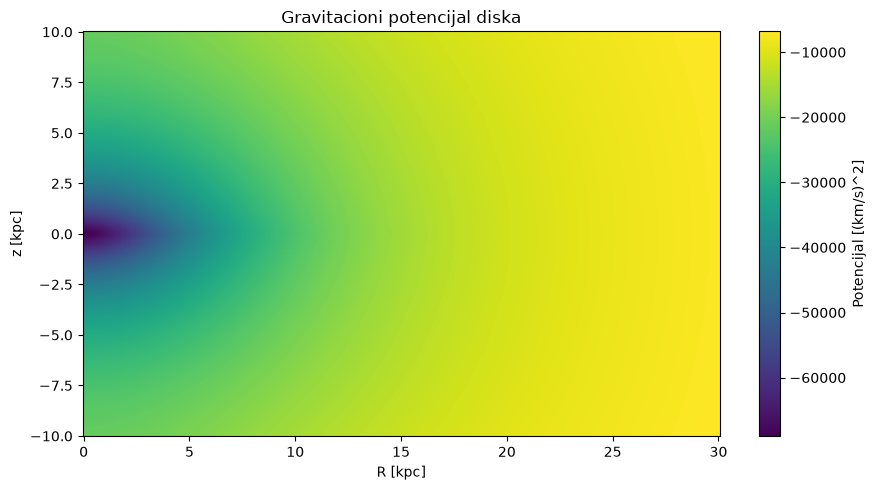

In [19]:
G = 4.30091e-6 #kpc(km/s)^2/M_sun #grav. konstanta
R = np.linspace(0, 30, 301) #radijus #0.01kpc
z = np.linspace(-10, 10, 401) #visina #0.05kpc
RR, ZZ = np.meshgrid(R, z, indexing="ij") #dvodimenzionalna mreza niza

rho = rho0 * np.exp(-RR/R_d) * np.exp(-np.abs(ZZ)/z_d) #gustinu opisujemo modelom dvosturko ekponencijalnog diska
Phi = solve_poisson(rho, R, z, M_disk, G) #resavamo poasnom 

print(f"Najmanji potencijal: {Phi.min():.1f} (km/s)^2")
#plotujemo grafik
plt.figure(figsize=(9, 5))
plt.pcolormesh(RR, ZZ, Phi, shading="auto", cmap="viridis") #pravimo kolor mapu mreze u Phi 
plt.colorbar(label="Potencijal [(km/s)^2]")
plt.xlabel("R [kpc]")
plt.ylabel("z [kpc]")
plt.title("Gravitacioni potencijal diska")
plt.tight_layout()
plt.show()

Nakon primene granicnih uslova i resavanja sistema dobijamo gravitacioni potencijal u svakoj tački mreze, koji zatim prikazujemo dvodimenzionalnom mapom. Sa mape vidimo da je gravitacioni potencijal najveci u ravi oko centra diska. 

##### <font color="green">6. Koristeći prethodni izraz, prikazati rotacionu krivu. </font>

Ako znamo potencijal, brzinu rotacije možemo odrediti koristeći izraz:
$$ \frac{v_c^2}{R} = \frac{\delta\Phi}{\delta R} $$

Najveća brzina: 164.8 km/s
Položaj maksimuma: 6.8 kpc


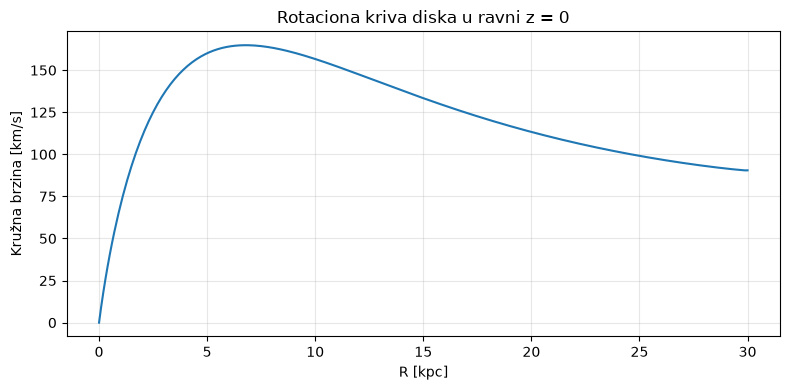

In [23]:
j0 = np.argmin(np.abs(z)) #indeks najmanje vrednosti
Phi_ravan = Phi[:, j0] #potencijal u ravni

dPhi_dR = np.gradient(Phi_ravan, R) #diferenciramo potencijal 
dPhi_dR[0] = 0 #granicni uslov
v_c = np.sqrt(R * dPhi_dR) #brzina

imax = np.argmax(v_c) #maksimalna brzina
print(f"Najveća brzina: {v_c[imax]:.1f} km/s")
print(f"Položaj maksimuma: {R[imax]:.1f} kpc")

plt.figure(figsize=(8, 4))
plt.plot(R, v_c)
plt.xlabel("R [kpc]")
plt.ylabel("Kružna brzina [km/s]")
plt.title("Rotaciona kriva diska u ravni z = 0")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Brzina prvo raste dostize 164.8 km/s na 6.8 kpc, a zatim opada. U centru galaksije vidimo da je brzina nula zbog uslova.

##### <font color="green">7. Odrediti brzinu Sunca iz ove rotacione krive i uporediti sa prihvaćenom vrednošću. </font> 

In [25]:
R_sunce = 8.122 #kpc udaljenost sunca od centra galasksije
v_ref = 229.0 # km/s referentna vrednost brzine
v_sunce = np.interp(R_sunce, R, v_c) #interpolacijom odredjujemo brzinu sunca
razlika = 100 * (v_sunce - v_ref) / v_ref #odnos brzina u procentima

print(f"Brzina u modelu: {v_sunce:.1f} km/s")
print(f"Referentna brzina: {v_ref:.1f} km/s")
print(f"Relativno odstupanje: {razlika:.1f} %")

Brzina u modelu: 163.1 km/s
Referentna brzina: 229.0 km/s
Relativno odstupanje: -28.8 %


Na polozaju Sunca model daje 163.1 km/s, što je oko 28.8% manje od referentnih 229 km/s. Na rezultat uticu i izabrani parametri diska, konačna mreza i priblizni granicni uslovi.

##### <font color="green">8. Kako se menja rotaciona kriva ako je ukupna masa diska dva puta veća, z nepromenjene vrednosti $R_d$ i $z_d$. </font> 

Prvobitna brzina na položaju Sunca: 163.1 km/s
Brzina za dvostruku masu: 230.6 km/s


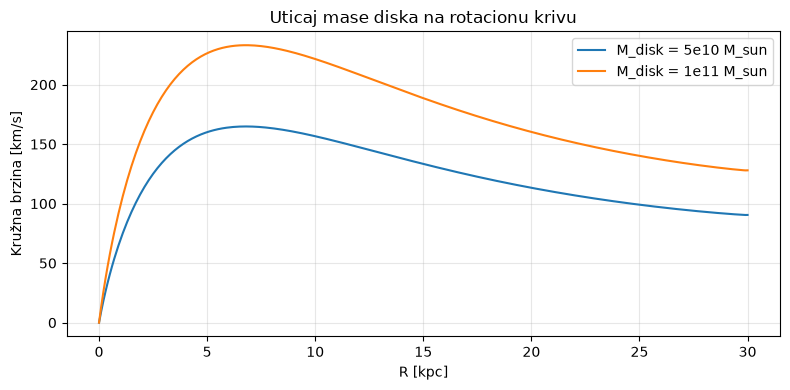

In [27]:
v_c_2 = np.sqrt(2) * v_c #ovo se dobija za brzinu kada imamo dvostruku masu 
v_sunce_2 = np.interp(R_sunce, R, v_c_2) #trazimo brzinu sunca pod novim uslovima

print(f"Prvobitna brzina na položaju Sunca: {v_sunce:.1f} km/s")
print(f"Brzina za dvostruku masu: {v_sunce_2:.1f} km/s")

plt.figure(figsize=(8, 4))
plt.plot(R, v_c, label="M_disk = 5e10 M_sun")
plt.plot(R, v_c_2, label="M_disk = 1e11 M_sun")
plt.xlabel("R [kpc]")
plt.ylabel("Kružna brzina [km/s]")
plt.title("Uticaj mase diska na rotacionu krivu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Dvostruko veca masa povecava sve brzine za faktor $\sqrt{2}\approx1.414$. Na polozaju Sunca brzina raste sa priblizno 163.1 na 230.6 km/s. Oblik krive i polozaj maksimuma ostaju isti. 